In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.0001
d = 0.7
alpha = 0.3
bound = 1 / (1 - d)

In [35]:
algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        random_uniform=False, tolerance=1e-10000, 
        M=int(5), verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()  
exp = np.random.randint(0, 5)
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]  

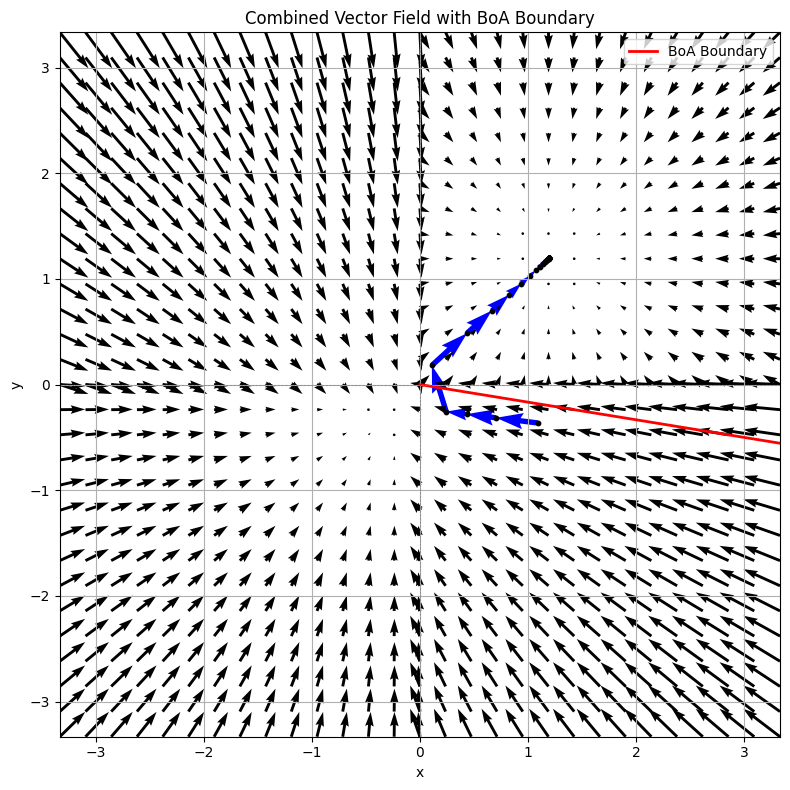

In [36]:
plotter = VectorFieldPlotter(q1 = q1, q2 = q2,
    t=t, r=r, p=p, s=s, alpha=alpha,
    bound=bound,
    epsilon=epsilon, d=d,
    q_func_gt=QvaluesGTvsGT,
    q_func_ad=QvaluesADvs00,
    x_state = 'StateC',
    y_state = 'StateC',
    show_trajectory=True,
    show_boundary=True
)
plotter.plot()